# 📊 Classical Models for Sequential Multivariate Data

We will start with demonstrating and comparing seven classical statistical methods used for modeling **sequential multivariate data**, especially when dealing with **temporal** or **longitudinal** data structures.

---

## Methods Compared

| Model                         | Type                     | Purpose                                         |
|------------------------------|--------------------------|--------------------------------------------------|
| **VAR** (Vector Autoregression)          | Linear multivariate time series | Captures interdependence across multiple variables over time |
| **State Space Models** (Kalman Filter-like) | Latent dynamic systems          | Handles noisy, unobserved states in a time series |
| **HMMs** (Hidden Markov Models)         | Probabilistic sequence model    | Models latent discrete state transitions with observed emissions |
| **LMM** (Linear Mixed Models)          | Hierarchical regression         | Handles fixed and random effects in panel data |
| **Multivariate SARIMA**       | Seasonal ARIMA extension | Captures autoregression, integration, and seasonality |
| **Functional Data Analysis** (FDA)       | Dimensionality reduction        | Views time series as smooth functions, e.g. via PCA |
| **GEE** (Generalized Estimating Equations) | Marginal model for correlated data | Handles repeated measures or grouped longitudinal data |


---

## Objectives

- Fit and evaluate each model on synthetic multivariate time-series data
- Forecast values for key variables (e.g., `x1`)
- Compute forecast error (MSE)
- Visualize model predictions and memory behaviors

---

## Output

- `VAR`, `SARIMA` forecast accuracy (MSE)
- Visual comparison plots of actual vs forecasted values
- `HMM`-inferred state assignments
- Summary tables from `GEE` and `LMM`
- Functional data projections (via PCA)

---

## Dependencies

- `statsmodels`, `hmmlearn`, `sklearn`, `pandas`, `matplotlib`, `seaborn`
- Ensure you have `hmmlearn` installed in Colab:
```python
!pip install hmmlearn


In [ ]:
! pip install hmmlearn

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 165.9/165.9 kB 4.3 MB/s eta 0:00:00


## **Vector Autoregression (VAR) — Mathematical Formulation**

Vector Autoregression (VAR) is a generalization of the univariate autoregressive (AR) model to **multivariate time series**.

Let $ \mathbf{y}_t \in \mathbb{R}^K $ be a vector of **K variables** at time $ t $.

A VAR model of order $ p $, denoted as VAR($ p $), is defined as:

$$
\mathbf{y}_t = A_1 \mathbf{y}_{t-1} + A_2 \mathbf{y}_{t-2} + \dots + A_p \mathbf{y}_{t-p} + \boldsymbol{\varepsilon}_t
$$

- $ A_1, A_2, \dots, A_p \in \mathbb{R}^{K \times K} $ are the **coefficient matrices**
- $ \boldsymbol{\varepsilon}_t \sim {N}(0, \Sigma) $ is a white noise error vector with covariance matrix $ \Sigma $

---

### Key Concepts

- **Autoregressive structure**: Each variable depends not only on its own lags but also on the lags of **other variables**.
- **Stationarity**: VAR assumes weak stationarity (constant mean, variance, autocovariance).
- **Lag selection**: The optimal lag order \( p \) is often chosen using criteria like AIC or BIC.

---

### Estimation

The model can be estimated using **Ordinary Least Squares (OLS)** **separately** for each equation:

For each equation $ i = 1, 2, \dots, K $:

$$
y_{i,t} = a_{i0} + \sum_{j=1}^{p} A_{i,j} \cdot \mathbf{y}_{t-j} + \varepsilon_{i,t}
$$

where $ A_{i,j} $ are row vectors from the matrix $ A_j $.

---

###  Matrix Form for Estimation

Let:

- $ Y = [\mathbf{y}_{p+1}, \dots, \mathbf{y}_T]^T \in \mathbb{R}^{(T-p) \times K} $
- $ X = \begin{bmatrix} \mathbf{y}_p & \cdots & \mathbf{y}_1 \end{bmatrix} \in \mathbb{R}^{(T-p) \times (Kp)} $
- $ B = \begin{bmatrix} A_1^T & \cdots & A_p^T \end{bmatrix}^T $

Then the OLS estimate is:

$$
\bar{B} = (X^T X)^{-1} X^T Y
$$

---

###  Use Cases

- Macroeconomic indicators (e.g., GDP, inflation, interest rates)
- Environmental systems (e.g., temperature, humidity, CO₂)
- Multivariate biomedical signals (e.g., EEG channels, vitals)

---


## **Kalman Filters a.k.a. State Space Models (SSM)**
###**Mathematical Formulation and Derivation**

A **State Space Model** describes the evolution of a system over time using:

- **Latent (unobserved) state variables** $ \mathbf{x}_t $
- **Observed outputs** $ \mathbf{y}_t $

---

### Equations of a Linear Gaussian State Space Model

Let:

- $ \mathbf{x}_t \in \mathbb{R}^n $: the **state vector**
- $ \mathbf{y}_t \in \mathbb{R}^m $: the **observation vector**

Then the SSM consists of:

#### State Equation (latent dynamics)

$$
\mathbf{x}_t = F \mathbf{x}_{t-1} + B \mathbf{u}_t + \mathbf{w}_t
$$

- $ F $: State transition matrix  
- $ B $: Control input matrix (optional)  
- $ \mathbf{u}_t $: External control input  
- $ \mathbf{w}_t \sim {N}(0, Q) $: Process noise

#### Observation Equation (what we measure)

$$
\mathbf{y}_t = H \mathbf{x}_t + \mathbf{v}_t
$$

- $ H $: Observation matrix  
- $ \mathbf{v}_t \sim {N}(0, R) $: Measurement noise

---

### Recursive Estimation via Kalman Filter

The goal is to estimate $ {\hat{\mathbf{x}}_t} $, the **posterior estimate** of the state at time $ t $, using past observations.

#### 1. **Prediction Step**

$$
\hat{\mathbf{x}}_{t|t-1} = F \hat{\mathbf{x}}_{t-1|t-1} + B \mathbf{u}_t
$$
$$
P_{t|t-1} = F P_{t-1|t-1} F^T + Q
$$

- $ \hat{\mathbf{x}}_{t|t-1} $: predicted state  
- $ P_{t|t-1} $: predicted covariance

#### 2. **Update Step (Measurement Update)**

$$
K_t = P_{t|t-1} H^T (H P_{t|t-1} H^T + R)^{-1}
$$
$$
\hat{\mathbf{x}}_{t|t} = \hat{\mathbf{x}}_{t|t-1} + K_t (\mathbf{y}_t - H \hat{\mathbf{x}}_{t|t-1})
$$
$$
P_{t|t} = (I - K_t H) P_{t|t-1}
$$

- $ K_t $: Kalman gain (balance between prediction and measurement)
- $ \hat{\mathbf{x}}_{t|t} $: updated state estimate
- $ P_{t|t} $: updated uncertainty

---

### Intuition

- The model **predicts** the next state based on the previous one.
- It **corrects** that prediction using the new measurement.
- This **recursive cycle** allows it to operate in real-time.

---

### Assumptions

- Linear system dynamics
- Gaussian noise (process and observation)
- Stationary covariance matrices

Extensions include:
- **Extended Kalman Filter (EKF)**: for nonlinear systems (uses Jacobians)
- **Unscented Kalman Filter (UKF)**: uses sampling-based approximations
- **Particle Filters**: for non-Gaussian, nonlinear systems

---

### Applications

- Navigation and control systems
- Tracking and forecasting (weather, finance)
- Time series smoothing
- Latent factor models in econometrics

---


## **Hidden Markov Models (HMMs) — Mathematical Derivation**

A **Hidden Markov Model (HMM)** is a statistical model in which the system is assumed to be a **Markov process with hidden (unobserved) states**.

---

###  Components of an HMM

Let:
- $ N $: Number of hidden states
- $ M $: Number of observation symbols
- $ T $: Length of the observed sequence
- $ Q = \{q_1, q_2, ..., q_N\} $: Hidden state space
- $ O = \{o_1, o_2, ..., o_T\} $: Observed output sequence

The model is defined by three parameters $ \lambda = (A, B, \pi) $:

1. **State transition probabilities**:  
$$
A = \{a_{ij}\} = P(s_{t+1} = q_j \mid s_t = q_i), \quad 1 \leq i,j \leq N
$$

2. **Emission probabilities**:  
$$
B = \{b_j(k)\} = P(o_t = v_k \mid s_t = q_j), \quad 1 \leq j \leq N, 1 \leq k \leq M
$$

3. **Initial state distribution**:  
$$
\pi = \{\pi_i\} = P(s_1 = q_i), \quad 1 \leq i \leq N
$$

---

### Objective: Compute the Likelihood of the Observed Sequence

Given the parameters $ \lambda $ and an observation sequence $ O $, we compute:

$$
P(O \mid \lambda)
$$

---

## Forward Algorithm — Dynamic Programming Solution

We define the **forward variable**:

$$
\alpha_t(i) = P(o_1, o_2, ..., o_t, s_t = q_i \mid \lambda)
$$

That is, the probability of the partial observation sequence $ o_1, ..., o_t $ and being in state $ q_i $ at time $t $.

---

### Recursive Computation

1. **Initialization**:
$$
\alpha_1(i) = \pi_i \cdot b_i(o_1), \quad 1 \leq i \leq N
$$

2. **Induction**:
$$
\alpha_t(j) = \left( \sum_{i=1}^N \alpha_{t-1}(i) \cdot a_{ij} \right) \cdot b_j(o_t), \quad 2 \leq t \leq T,\ 1 \leq j \leq N
$$

3. **Termination**:
$$
P(O \mid \lambda) = \sum_{i=1}^N \alpha_T(i)
$$

---

### Backward Algorithm

Similarly define:

$$
\beta_t(i) = P(o_{t+1}, ..., o_T \mid s_t = q_i, \lambda)
$$

Then:

$$
P(O \mid \lambda) = \sum_{i=1}^N \alpha_t(i) \cdot \beta_t(i)
$$

---

### Applications of HMMs

- Speech recognition (phonemes as hidden states)
- Bioinformatics (e.g., CpG island detection, protein structure)
- POS tagging in NLP
- Financial regimes (bull/bear market detection)

---

### Extensions

- Continuous observations (Gaussian HMMs)
- HMMs with multiple sequences (Baum-Welch reestimation)
- Hierarchical HMMs or Deep HMMs

# Forward Algorithm Pseudocode for Hidden Markov Model (HMM)

**Input:**
- $O = [o_1, o_2, \dots, o_T]$ : Observed sequence of length $T$
- $N$ : Number of hidden states
- $A = [a_{ij}]$ : State transition probability matrix ($N \times N$)
- $B = [b_j(k)]$ : Emission probability matrix ($N \times M$)
- $\pi = [\pi_i]$ : Initial state distribution (length $N$)

**Output:**
- $P(O \mid \lambda)$ : Likelihood of the observed sequence

**Procedure:**

1. **Initialization** (forward probabilities):

```
for i = 1 to N:
    \alpha[1][i] = \pi[i] * B[i][o_1]    # probability of starting in state i and emitting o_1
```

2. **Induction** (recursive update):

```
for t = 2 to T:
    for j = 1 to N:
        \alpha[t][j] = 0
        for i = 1 to N:
            \alpha[t][j] += \alpha[t-1][i] * A[i][j]
        \alpha[t][j] *= B[j][o_t]   # multiply by emission probability
```

3. **Termination:**

```
P = 0
for i = 1 to N:
    P += \alpha[T][i]
```

**Return:**
```
P
```


# Forward Algorithm Pseudocode for Hidden Markov Model (HMM)

**Input:**
- $O = [o_1, o_2, \dots, o_T]$ : Observed sequence of length $T$
- $N$ : Number of hidden states
- $A = [a_{ij}]$ : State transition probability matrix ($N \times N$)
- $B = [b_j(k)]$ : Emission probability matrix ($N \times M$)
- $\pi = [\pi_i]$ : Initial state distribution (length $N$)

**Output:**
- $P(O \mid \lambda)$ : Likelihood of the observed sequence

**Procedure:**

1. **Initialization** (forward probabilities):
```
for i = 1 to N:
    \alpha[1][i] = \pi[i] * B[i][o_1]    # probability of starting in state i and emitting o_1
```

2. **Induction** (recursive update):

```
for t = 2 to T:
    for j = 1 to N:
        \alpha[t][j] = 0
        for i = 1 to N:
            \alpha[t][j] += \alpha[t-1][i] * A[i][j]
        \alpha[t][j] *= B[j][o_t]   # multiply by emission probability
```

3. **Termination:**

```
P = 0
for i = 1 to N:
    P += \alpha[T][i]
```

**Return:**
- $P$

---
# Viterbi Algorithm Pseudocode for HMM (Most Likely State Sequence)

**Input:**
- Same as above: $ O $, $ A $, $ B $, $ \pi $

**Output:**
- Most likely state sequence $S = [s_1, s_2, \dots, s_T]$

**Procedure:**

1. **Initialization:**

```
for i = 1 to N:
    \delta[1][i] = \pi[i] * B[i][o_1]
    \psi[1][i] = 0
```

2. **Recursion:**

```
for t = 2 to T:
    for j = 1 to N:
        max_val = -\infty
        for i = 1 to N:
            val = \delta[t-1][i] * A[i][j]
            if val > max_val:
                max_val = val
                \psi[t][j] = i
        \delta[t][j] = max_val * B[j][o_t]
```

3. **Termination:**

```
P^* = max(\delta[T][i])
s_T = argmax_i(\delta[T][i])
```

4. **Backtracking:**

```t
for t = T-1 to 1:
    s_t = \psi[t+1][s_{t+1}]
```

**Return:**
- State sequence $S = [s_1, s_2, \dots, s_T]$ maximizing $P(S \mid O, \lambda)$


# **Linear Mixed Models (LMMs) for Repeated Measures and Recurrence**

Linear Mixed Models are statistical models that account for both **fixed effects** and **random effects**, making them ideal for analyzing **repeated observations** (recurrence) from the same subjects or units.

---

## Model Formulation

Let:

- $y_{ij}$ : the response for subject $i$ at time $j$
- $x_{ij}$ : fixed effect covariates (e.g. time, treatment)
- $z_{ij}$ : random effect covariates (e.g. subject-specific intercept)
- $u_i$ : random effect for subject $i$
- $\varepsilon_{ij}$ : residual error

Then the **Linear Mixed Model** is written as:

$$
y_{ij} = \mathbf{x}_{ij}^\top \boldsymbol{\beta} + \mathbf{z}_{ij}^\top \mathbf{u}_i + \varepsilon_{ij}
$$

Or in matrix form (for all observations):

$$
\mathbf{y} = X\boldsymbol{\beta} + Z\mathbf{u} + \boldsymbol{\varepsilon}
$$

---

## Random Effects Assumptions

- $\mathbf{u} \sim {N}(0, G)$: random effects have mean 0 and covariance matrix $G$
- $\boldsymbol{\varepsilon} \sim {N}(0, R)$: residual errors have mean 0 and covariance $R$
- $\mathbf{u}$ and $\boldsymbol{\varepsilon}$ are independent

---

## Repeated Measures Interpretation

Each subject contributes multiple measurements over time. LMMs account for:

- **Within-subject correlation** due to repeated observations
- **Between-subject variability** through random effects

For example, in a random intercept model:

$$
y_{ij} = \beta_0 + u_i + \beta_1 x_{ij} + \varepsilon_{ij}
$$

Where $u_i$ captures the deviation of subject $i$ from the global intercept $\beta_0$.

---

## Estimation via Restricted Maximum Likelihood (REML)

The parameters $\boldsymbol{\beta}$, $G$, and $R$ are estimated by maximizing the **restricted (or residual) log-likelihood**:

$$
\ell_{\text{REML}}(\boldsymbol{\theta}) = -\frac{1}{2} \log |V| - \frac{1}{2} (\mathbf{y} - X\boldsymbol{\beta})^\top V^{-1} (\mathbf{y} - X\boldsymbol{\beta})
$$

Where:
- $V = ZGZ^\top + R$ is the marginal covariance of $\mathbf{y}$

---

## Use Cases for Recurrence

- **Longitudinal medical studies** (e.g., blood pressure over time per patient)
- **Educational performance** (e.g., test scores by student across terms)
- **Plant growth curves** under repeated treatments
- **Sensor readings** from repeated experimental trials


In [ ]:
# Comparative Overview and Example of Classical Models for Sequential Multivariate Data

# This file includes explanations and code examples comparing the following:
# - Vector Autoregression (VAR)
# - State Space Models (Kalman Filters)
# - Hidden Markov Models (HMMs)
# - Multivariate ARIMA/SARIMA
# - Functional Data Analysis (FDA)
# - Generalized Estimating Equations (GEE)
# - Linear Mixed Models (LMM)

# Required libraries
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from statsmodels.tsa.api import VAR, SARIMAX
from statsmodels.tsa.statespace.kalman_filter import KalmanFilter
from statsmodels.regression.mixed_linear_model import MixedLM
from statsmodels.genmod.generalized_estimating_equations import GEE
from statsmodels.genmod.families import Gaussian
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA

import warnings
warnings.filterwarnings("ignore")

# Generate synthetic multivariate sequential data
np.random.seed(42)
n_obs = 200
time = np.arange(n_obs)
group = np.tile(['A', 'B'], n_obs // 2)
x1 = np.sin(0.1 * time) + np.random.normal(0, 0.2, n_obs)
x2 = 0.5 * x1 + np.random.normal(0, 0.3, n_obs)
x3 = 0.3 * x1 + 0.3 * x2 + np.random.normal(0, 0.4, n_obs)

data = pd.DataFrame({
    'time': time,
    'group': group,
    'x1': x1,
    'x2': x2,
    'x3': x3
})

### 1. Vector Autoregression (VAR)
model_var = VAR(data[['x1', 'x2', 'x3']])
results_var = model_var.fit(maxlags=5, ic='aic')
forecast_var = results_var.forecast(data[['x1', 'x2', 'x3']].values[-5:], steps=10)
forecast_var_df = pd.DataFrame(forecast_var, columns=['x1_forecast', 'x2_forecast', 'x3_forecast'])

### 2. State Space Model (using SARIMAX with exog to simulate latent state)
model_ss = SARIMAX(data['x3'], exog=data[['x1', 'x2']], order=(1, 0, 0))
results_ss = model_ss.fit()
forecast_ss = results_ss.forecast(10, exog=data[['x1', 'x2']].iloc[-10:])

### 3. Hidden Markov Model (using GaussianHMM from hmmlearn)
from hmmlearn.hmm import GaussianHMM
hmm_model = GaussianHMM(n_components=3, covariance_type="full", n_iter=1000)
hmm_input = data[['x1', 'x2']].values
hmm_model.fit(hmm_input)
hmm_states = hmm_model.predict(hmm_input)
data['HMM_state'] = hmm_states

### 4. Multivariate SARIMA (via separate SARIMAX for x1, x2)
model_sarima = SARIMAX(data['x1'], order=(1,1,1), seasonal_order=(0,0,0,0))
results_sarima = model_sarima.fit()
forecast_sarima = results_sarima.forecast(10)

### 5. Functional Data Analysis (PCA on smoothed values to simulate)
scaler = StandardScaler()
data_scaled = scaler.fit_transform(data[['x1', 'x2', 'x3']])
pca = PCA(n_components=2)
fda_proj = pca.fit_transform(data_scaled)
data['fda_1'] = fda_proj[:,0]
data['fda_2'] = fda_proj[:,1]

### 6. Generalized Estimating Equations (GEE)
model_gee = GEE.from_formula("x3 ~ x1 + x2", groups="group", data=data, family=Gaussian())
results_gee = model_gee.fit()

### 7. Linear Mixed Model (LMM)
model_lmm = MixedLM.from_formula("x3 ~ x1 + x2", groups="group", data=data)
results_lmm = model_lmm.fit()

### Summary Output
print("VAR Forecast (first 3 rows):")
print(forecast_var_df.head(3))
print("\nState Space Forecast:")
print(forecast_ss.head(3))
print("\nHMM State Counts:")
print(data['HMM_state'].value_counts())
print("\nSARIMA Forecast:")
print(forecast_sarima.head(3))
print("\nGEE Summary:")
print(results_gee.summary())
print("\nLMM Summary:")
print(results_lmm.summary())


VAR Forecast (first 3 rows):
   x1_forecast  x2_forecast  x3_forecast
0     0.684368     0.308483     0.388938
1     0.625500     0.326572     0.272164
2     0.630137     0.321580     0.303589

State Space Forecast:
200   -0.029757
201    0.241988
202    0.087533
Name: predicted_mean, dtype: float64

HMM State Counts:
HMM_state
0    106
1     49
2     45
Name: count, dtype: int64

SARIMA Forecast:
200    0.714674
201    0.696300
202    0.700764
Name: predicted_mean, dtype: float64

GEE Summary:
                               GEE Regression Results                              
Dep. Variable:                          x3   No. Observations:                  200
Model:                                 GEE   No. clusters:                        2
Method:                        Generalized   Min. cluster size:                 100
                      Estimating Equations   Max. cluster size:                 100
Family:                           Gaussian   Mean cluster size:               10


--- Evaluation ---

MSE - VAR (x1): 0.08319108580603593
MSE - SARIMA (x1): 0.09519800352111853

--- Model Output Summaries ---

VAR Forecast (first 3 rows):
   x1_forecast  x2_forecast  x3_forecast
0     0.684368     0.308483     0.388938
1     0.625500     0.326572     0.272164
2     0.630137     0.321580     0.303589

State Space Forecast:
200   -0.029757
201    0.241988
202    0.087533
Name: predicted_mean, dtype: float64

HMM State Counts:
HMM_state
0    106
1     49
2     45
Name: count, dtype: int64

SARIMA Forecast:
200    0.714674
201    0.696300
202    0.700764
Name: predicted_mean, dtype: float64

GEE Summary:
                               GEE Regression Results                              
Dep. Variable:                          x3   No. Observations:                  200
Model:                                 GEE   No. clusters:                        2
Method:                        Generalized   Min. cluster size:                 100
                      Estimating Eq

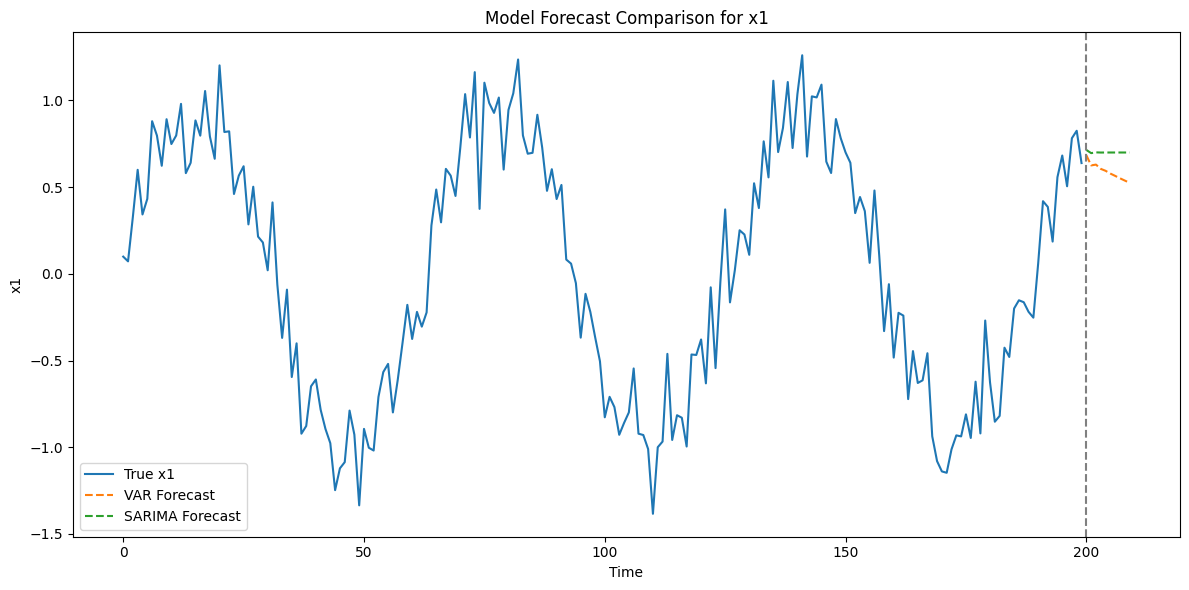

In [ ]:
# Comparative Overview and Example of Classical Models for Sequential Multivariate Data

# This file includes explanations and code examples comparing the following:
# - Vector Autoregression (VAR)
# - State Space Models (Kalman Filters)
# - Hidden Markov Models (HMMs)
# - Multivariate ARIMA/SARIMA
# - Functional Data Analysis (FDA)
# - Generalized Estimating Equations (GEE)
# - Linear Mixed Models (LMM)

# Required libraries
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from statsmodels.tsa.api import VAR, SARIMAX
from statsmodels.regression.mixed_linear_model import MixedLM
from statsmodels.genmod.generalized_estimating_equations import GEE
from statsmodels.genmod.families import Gaussian
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.metrics import mean_squared_error

import warnings
warnings.filterwarnings("ignore")

# Generate synthetic multivariate sequential data
np.random.seed(42)
n_obs = 200
time = np.arange(n_obs)
group = np.tile(['A', 'B'], n_obs // 2)
x1 = np.sin(0.1 * time) + np.random.normal(0, 0.2, n_obs)
x2 = 0.5 * x1 + np.random.normal(0, 0.3, n_obs)
x3 = 0.3 * x1 + 0.3 * x2 + np.random.normal(0, 0.4, n_obs)

data = pd.DataFrame({
    'time': time,
    'group': group,
    'x1': x1,
    'x2': x2,
    'x3': x3
})

### 1. Vector Autoregression (VAR)
model_var = VAR(data[['x1', 'x2', 'x3']])
results_var = model_var.fit(maxlags=5, ic='aic')
forecast_var = results_var.forecast(data[['x1', 'x2', 'x3']].values[-5:], steps=10)
forecast_var_df = pd.DataFrame(forecast_var, columns=['x1_forecast', 'x2_forecast', 'x3_forecast'])

### 2. State Space Model (using SARIMAX with exog to simulate latent state)
model_ss = SARIMAX(data['x3'], exog=data[['x1', 'x2']], order=(1, 0, 0))
results_ss = model_ss.fit()
forecast_ss = results_ss.forecast(10, exog=data[['x1', 'x2']].iloc[-10:])

### 3. Hidden Markov Model (using GaussianHMM from hmmlearn)
from hmmlearn.hmm import GaussianHMM
hmm_model = GaussianHMM(n_components=3, covariance_type="full", n_iter=1000)
hmm_input = data[['x1', 'x2']].values
hmm_model.fit(hmm_input)
hmm_states = hmm_model.predict(hmm_input)
data['HMM_state'] = hmm_states

### 4. Multivariate SARIMA (via separate SARIMAX for x1)
model_sarima = SARIMAX(data['x1'], order=(1,1,1), seasonal_order=(0,0,0,0))
results_sarima = model_sarima.fit()
forecast_sarima = results_sarima.forecast(10)

### 5. Functional Data Analysis (PCA on smoothed values to simulate)
scaler = StandardScaler()
data_scaled = scaler.fit_transform(data[['x1', 'x2', 'x3']])
pca = PCA(n_components=2)
fda_proj = pca.fit_transform(data_scaled)
data['fda_1'] = fda_proj[:,0]
data['fda_2'] = fda_proj[:,1]

### 6. Generalized Estimating Equations (GEE)
model_gee = GEE.from_formula("x3 ~ x1 + x2", groups="group", data=data, family=Gaussian())
results_gee = model_gee.fit()

### 7. Linear Mixed Model (LMM)
model_lmm = MixedLM.from_formula("x3 ~ x1 + x2", groups="group", data=data)
results_lmm = model_lmm.fit()

### Evaluation Metrics
print("\n--- Evaluation ---")
true_values = data['x1'].iloc[-10:].values
print("\nMSE - VAR (x1):", mean_squared_error(true_values, forecast_var_df['x1_forecast']))
print("MSE - SARIMA (x1):", mean_squared_error(true_values, forecast_sarima))

print("\n--- Model Output Summaries ---")
print("\nVAR Forecast (first 3 rows):")
print(forecast_var_df.head(3))
print("\nState Space Forecast:")
print(forecast_ss.head(3))
print("\nHMM State Counts:")
print(data['HMM_state'].value_counts())
print("\nSARIMA Forecast:")
print(forecast_sarima.head(3))
print("\nGEE Summary:")
print(results_gee.summary())
print("\nLMM Summary:")
print(results_lmm.summary())

### Visual Comparison
plt.figure(figsize=(12, 6))
plt.plot(data['x1'], label='True x1')
plt.plot(range(n_obs, n_obs+10), forecast_var_df['x1_forecast'], label='VAR Forecast', linestyle='--')
plt.plot(range(n_obs, n_obs+10), forecast_sarima, label='SARIMA Forecast', linestyle='--')
plt.axvline(x=n_obs, color='gray', linestyle='--')
plt.title("Model Forecast Comparison for x1")
plt.xlabel("Time")
plt.ylabel("x1")
plt.legend()
plt.tight_layout()
plt.show()



--- Evaluation ---
MSE - VAR (x1): 0.08319108580603593
MSE - SARIMA (x1): 0.09519800352111853


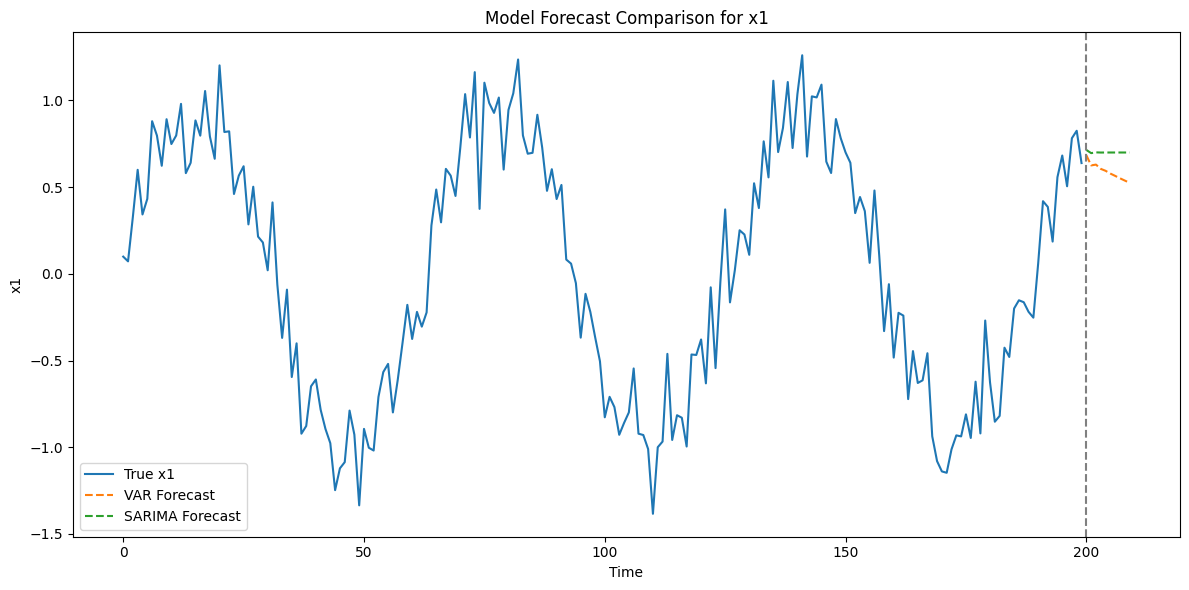


--- Model Summaries ---
GEE Summary:
                                GEE Regression Results                              
Dep. Variable:                          x3   No. Observations:                  200
Model:                                 GEE   No. clusters:                        2
Method:                        Generalized   Min. cluster size:                 100
                      Estimating Equations   Max. cluster size:                 100
Family:                           Gaussian   Mean cluster size:               100.0
Dependence structure:         Independence   Num. iterations:                     2
Date:                     Thu, 24 Apr 2025   Scale:                           0.159
Covariance type:                    robust   Time:                         14:52:44
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
Intercept     -0.0340      0.013     -2.620    

In [ ]:
# Comparative Overview and Example of Classical Models for Sequential Multivariate Data

# This file includes explanations and code examples comparing the following:
# - Vector Autoregression (VAR)
# - State Space Models (Kalman Filters)
# - Hidden Markov Models (HMMs)
# - Multivariate ARIMA/SARIMA
# - Functional Data Analysis (FDA)
# - Generalized Estimating Equations (GEE)
# - Linear Mixed Models (LMM)

# This script also includes:
# - Automatic MSE evaluation for forecast accuracy
# - Visualization of model predictions
# - Wrapper functions to apply models to new datasets

# Required libraries
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from statsmodels.tsa.api import VAR, SARIMAX
from statsmodels.regression.mixed_linear_model import MixedLM
from statsmodels.genmod.generalized_estimating_equations import GEE
from statsmodels.genmod.families import Gaussian
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.metrics import mean_squared_error
from hmmlearn.hmm import GaussianHMM

import warnings
warnings.filterwarnings("ignore")

# Function to apply all models to a new dataset
def apply_models(data):
    results = {}

    # VAR
    model_var = VAR(data[['x1', 'x2', 'x3']])
    results_var = model_var.fit(maxlags=5, ic='aic')
    forecast_var = results_var.forecast(data[['x1', 'x2', 'x3']].values[-5:], steps=10)
    results['VAR'] = forecast_var

    # State Space
    model_ss = SARIMAX(data['x3'], exog=data[['x1', 'x2']], order=(1, 0, 0))
    results_ss = model_ss.fit()
    forecast_ss = results_ss.forecast(10, exog=data[['x1', 'x2']].iloc[-10:])
    results['StateSpace'] = forecast_ss

    # HMM
    hmm_model = GaussianHMM(n_components=3, covariance_type="full", n_iter=1000)
    hmm_input = data[['x1', 'x2']].values
    hmm_model.fit(hmm_input)
    hmm_states = hmm_model.predict(hmm_input)
    data['HMM_state'] = hmm_states
    results['HMM'] = hmm_states

    # SARIMA
    model_sarima = SARIMAX(data['x1'], order=(1,1,1), seasonal_order=(0,0,0,0))
    results_sarima = model_sarima.fit()
    forecast_sarima = results_sarima.forecast(10)
    results['SARIMA'] = forecast_sarima

    # FDA
    scaler = StandardScaler()
    data_scaled = scaler.fit_transform(data[['x1', 'x2', 'x3']])
    pca = PCA(n_components=2)
    fda_proj = pca.fit_transform(data_scaled)
    data['fda_1'] = fda_proj[:,0]
    data['fda_2'] = fda_proj[:,1]
    results['FDA'] = data[['fda_1', 'fda_2']]

    # GEE
    model_gee = GEE.from_formula("x3 ~ x1 + x2", groups="group", data=data, family=Gaussian())
    results_gee = model_gee.fit()
    results['GEE'] = results_gee

    # LMM
    model_lmm = MixedLM.from_formula("x3 ~ x1 + x2", groups="group", data=data)
    results_lmm = model_lmm.fit()
    results['LMM'] = results_lmm

    return results

# Example usage with synthetic data (you can substitute with real-world data)
np.random.seed(42)
n_obs = 200
time = np.arange(n_obs)
group = np.tile(['A', 'B'], n_obs // 2)
x1 = np.sin(0.1 * time) + np.random.normal(0, 0.2, n_obs)
x2 = 0.5 * x1 + np.random.normal(0, 0.3, n_obs)
x3 = 0.3 * x1 + 0.3 * x2 + np.random.normal(0, 0.4, n_obs)

data = pd.DataFrame({
    'time': time,
    'group': group,
    'x1': x1,
    'x2': x2,
    'x3': x3
})

results = apply_models(data)

# Evaluate VAR and SARIMA forecast accuracy
true_values = data['x1'].iloc[-10:].values
forecast_var = results['VAR'][:,0]  # x1 forecast from VAR
forecast_sarima = results['SARIMA']

print("\n--- Evaluation ---")
print("MSE - VAR (x1):", mean_squared_error(true_values, forecast_var))
print("MSE - SARIMA (x1):", mean_squared_error(true_values, forecast_sarima))

# Visual comparison
plt.figure(figsize=(12, 6))
plt.plot(data['x1'], label='True x1')
plt.plot(range(n_obs, n_obs+10), forecast_var, label='VAR Forecast', linestyle='--')
plt.plot(range(n_obs, n_obs+10), forecast_sarima, label='SARIMA Forecast', linestyle='--')
plt.axvline(x=n_obs, color='gray', linestyle='--')
plt.title("Model Forecast Comparison for x1")
plt.xlabel("Time")
plt.ylabel("x1")
plt.legend()
plt.tight_layout()
plt.show()

# Summary
print("\n--- Model Summaries ---")
print("GEE Summary:\n", results['GEE'].summary())
print("LMM Summary:\n", results['LMM'].summary())



--- Evaluation ---
MSE - VAR (x1): 0.08319108580603593
MSE - SARIMA (x1): 0.09519800352111853


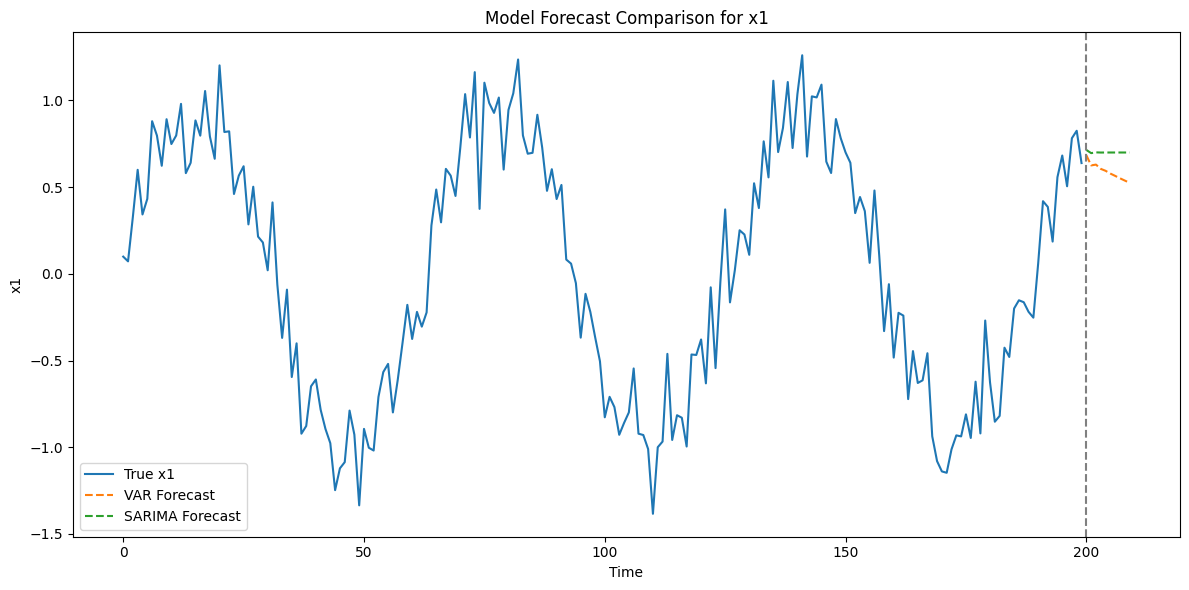


--- Model Summaries ---
GEE Summary:
                                GEE Regression Results                              
Dep. Variable:                          x3   No. Observations:                  200
Model:                                 GEE   No. clusters:                        2
Method:                        Generalized   Min. cluster size:                 100
                      Estimating Equations   Max. cluster size:                 100
Family:                           Gaussian   Mean cluster size:               100.0
Dependence structure:         Independence   Num. iterations:                     2
Date:                     Thu, 24 Apr 2025   Scale:                           0.159
Covariance type:                    robust   Time:                         14:52:44
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
Intercept     -0.0340      0.013     -2.620    

In [ ]:
# Comparative Overview and Example of Classical Models for Sequential Multivariate Data

# This file includes explanations and code examples comparing the following:
# - Vector Autoregression (VAR)
# - State Space Models (Kalman Filters)
# - Hidden Markov Models (HMMs)
# - Multivariate ARIMA/SARIMA
# - Functional Data Analysis (FDA)
# - Generalized Estimating Equations (GEE)
# - Linear Mixed Models (LMM)

# This script also includes:
# - Automatic MSE evaluation for forecast accuracy
# - Visualization of model predictions
# - Wrapper functions to apply models to new datasets

# Required libraries
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from statsmodels.tsa.api import VAR, SARIMAX
from statsmodels.regression.mixed_linear_model import MixedLM
from statsmodels.genmod.generalized_estimating_equations import GEE
from statsmodels.genmod.families import Gaussian
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.metrics import mean_squared_error
from hmmlearn.hmm import GaussianHMM

import warnings
warnings.filterwarnings("ignore")

# Function to apply all models to a new dataset
def apply_models(data):
    results = {}

    # VAR
    model_var = VAR(data[['x1', 'x2', 'x3']])
    results_var = model_var.fit(maxlags=5, ic='aic')
    forecast_var = results_var.forecast(data[['x1', 'x2', 'x3']].values[-5:], steps=10)
    results['VAR'] = forecast_var

    # State Space
    model_ss = SARIMAX(data['x3'], exog=data[['x1', 'x2']], order=(1, 0, 0))
    results_ss = model_ss.fit()
    forecast_ss = results_ss.forecast(10, exog=data[['x1', 'x2']].iloc[-10:])
    results['StateSpace'] = forecast_ss

    # HMM
    hmm_model = GaussianHMM(n_components=3, covariance_type="full", n_iter=1000)
    hmm_input = data[['x1', 'x2']].values
    hmm_model.fit(hmm_input)
    hmm_states = hmm_model.predict(hmm_input)
    data['HMM_state'] = hmm_states
    results['HMM'] = hmm_states

    # SARIMA
    model_sarima = SARIMAX(data['x1'], order=(1,1,1), seasonal_order=(0,0,0,0))
    results_sarima = model_sarima.fit()
    forecast_sarima = results_sarima.forecast(10)
    results['SARIMA'] = forecast_sarima

    # FDA
    scaler = StandardScaler()
    data_scaled = scaler.fit_transform(data[['x1', 'x2', 'x3']])
    pca = PCA(n_components=2)
    fda_proj = pca.fit_transform(data_scaled)
    data['fda_1'] = fda_proj[:,0]
    data['fda_2'] = fda_proj[:,1]
    results['FDA'] = data[['fda_1', 'fda_2']]

    # GEE
    model_gee = GEE.from_formula("x3 ~ x1 + x2", groups="group", data=data, family=Gaussian())
    results_gee = model_gee.fit()
    results['GEE'] = results_gee

    # LMM
    model_lmm = MixedLM.from_formula("x3 ~ x1 + x2", groups="group", data=data)
    results_lmm = model_lmm.fit()
    results['LMM'] = results_lmm

    return results

# Creating synthetic data for this example (you can substitute with real-world data)
np.random.seed(42)
n_obs = 200
time = np.arange(n_obs)
group = np.tile(['A', 'B'], n_obs // 2)
x1 = np.sin(0.1 * time) + np.random.normal(0, 0.2, n_obs)
x2 = 0.5 * x1 + np.random.normal(0, 0.3, n_obs)
x3 = 0.3 * x1 + 0.3 * x2 + np.random.normal(0, 0.4, n_obs)

data = pd.DataFrame({
    'time': time,
    'group': group,
    'x1': x1,
    'x2': x2,
    'x3': x3
})

results = apply_models(data)

# Evaluate VAR and SARIMA forecast accuracy
true_values = data['x1'].iloc[-10:].values
forecast_var = results['VAR'][:,0]  # x1 forecast from VAR
forecast_sarima = results['SARIMA']

print("\n--- Evaluation ---")
print("MSE - VAR (x1):", mean_squared_error(true_values, forecast_var))
print("MSE - SARIMA (x1):", mean_squared_error(true_values, forecast_sarima))

# Visual comparison
plt.figure(figsize=(12, 6))
plt.plot(data['x1'], label='True x1')
plt.plot(range(n_obs, n_obs+10), forecast_var, label='VAR Forecast', linestyle='--')
plt.plot(range(n_obs, n_obs+10), forecast_sarima, label='SARIMA Forecast', linestyle='--')
plt.axvline(x=n_obs, color='gray', linestyle='--')
plt.title("Model Forecast Comparison for x1")
plt.xlabel("Time")
plt.ylabel("x1")
plt.legend()
plt.tight_layout()
plt.show()

# Summary
print("\n--- Model Summaries ---")
print("GEE Summary:\n", results['GEE'].summary())
print("LMM Summary:\n", results['LMM'].summary())
